<a href="https://colab.research.google.com/github/Joao-Nelson-Cruz/Exercicios_com_testes_parametricos_e_nao_parametricos/blob/main/Pr%C3%A1tica_em_An%C3%A1lise_Estat%C3%ADstica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **EXERCÍCIOS PROPOSTOS**

In [ ]:
import pandas as pd

# Conjunto de dados TechTaste
df_techtaste = pd.DataFrame({'avaliacoes': [38, 44, 33, 42, 47, 33, 36, 39, 42, 36, 39, 34, 42, 42, 36, 43, 31, 35, 36, 41, 42, 30, 25, 38, 47, 36, 32, 45, 44, 45, 37, 48, 37, 36, 44, 49, 31, 45, 45, 40, 36, 50, 38, 34, 36, 42, 46, 49, 36, 34, 38, 31, 53, 40, 57, 40, 36, 42, 26, 50, 32, 43, 35, 37, 42, 30, 36, 43, 40, 43, 44, 52, 37, 51, 35, 47, 40, 50, 37, 49]})

In [ ]:
# 1. Calcule o desvio padrão amostral das avaliações

desvio_padrao = df_techtaste.std().round(2)
desvio_padrao

,0
avaliacoes,6.42


In [ ]:
# 2. Calcule o erro padrão amostral da média para as avaliações dos clientes.

from scipy import stats

erro_padrao = stats.sem(df_techtaste['avaliacoes']).round(2)
erro_padrao

np.float64(0.72)

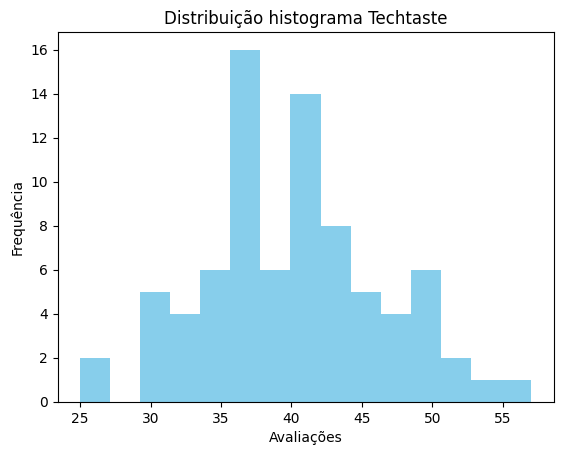

In [ ]:
# 3. Utilizando um gráfico de histograma, analise visualmente a distribuição das avaliações dos clientes.

import matplotlib.pyplot as plt

plt.hist(df_techtaste['avaliacoes'], bins = 15, color = 'skyblue')
plt.title('Distribuição histograma Techtaste')
plt.xlabel('Avaliações')
plt.ylabel('Frequência')
plt.show()

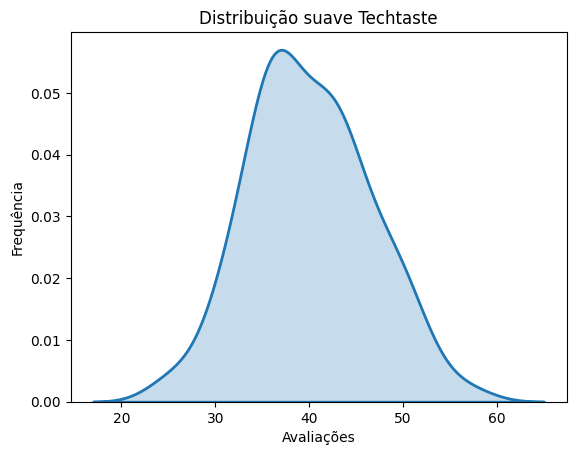

In [ ]:
# 4. Observe o formato da distribuição gerado no histograma. Ele se assemelha a uma distribuição normal?

import seaborn as sns

sns.kdeplot(df_techtaste['avaliacoes'], linewidth = 2, fill = True)

plt.xlabel('Avaliações')
plt.ylabel('Frequência')
plt.title('Distribuição suave Techtaste')
plt.show()

Em resposta a questão 4, a distruibuição suave deixa claro que há uma distribuição normal com o gráfico se concentrando em torno da média.

In [ ]:
# 5. Com um nível de confiança de 90%, calcule o intervalo de confiança para a média das avaliações.

confianca = 0.90
intervalo_confianca = stats.norm.interval(confianca,
                                          loc = df_techtaste['avaliacoes'].mean(),
                                          scale = erro_padrao)
print(f'Intervalo de Confiança ({confianca*100}%): {intervalo_confianca}.')

Intervalo de Confiança (90.0%): (np.float64(38.84070538859494), np.float64(41.209294611405056)).


In [ ]:
# 6. A largura do intervalo de confiança seria afetada se o nível de confiança fosse aumentado para 95%?

confianca = 0.95

intervalo_confianca = stats.norm.interval(confianca,
                                          loc = df_techtaste['avaliacoes'].mean(),
                                          scale = erro_padrao)
print(f'Intervalo de Confiança ({confianca*100}%): {intervalo_confianca}.')

Intervalo de Confiança (95.0%): (np.float64(38.61382593113116), np.float64(41.43617406886884)).


Em resposta a questão 6, o intervalo de confiança a 95% faz aumentar um pouco a amplitude do intervalo, mas o aumento ainda é discreto e nos mantém convergindo para a mesma média.

# **Para verificar se a estimativa formulada antes do lançamento do chat com IA está certa, a equipe de consultoria separou, novamente, algumas etapas:**

1. Calcule a média amostral das avaliações.
2. Formule hipóteses para o problema da empresa.
3. Estabelecidos o nível de confiança em 95% e o desvio padrão populacional em 2.65, verifique se a média da amostra está definida dentro do intervalo de confiança da hipótese nula.
4. O que é possível entender a partir do resultado da etapa anterior?
5. Utilize o Teste Z para calcular o valor da Estatística Z e o p-valor para o problema da TechTaste.
6. Pelos resultados anteriores, a hipótese nula formulada é rejeitada ou não rejeitada? Explique o que justifica sua decisão.

In [ ]:
media_amostral = df_techtaste['avaliacoes'].mean()
print(f'A média amostral é {media_amostral}.')

A média amostral é 40.025.


In [ ]:
# H0: μ = 30
# H1: μ = != 30

In [ ]:
import numpy as np

# valores de confianca especificados:
confianca = 0.95
desvio_padrao_populacional = 2.65

# Outros valores para calcular o intervalo:
tamanho_amostra = len(df_techtaste)
media_nula = 30

from scipy import stats
intervalo_confianca_amostra = stats.norm.interval(confianca,
                                           loc = media_nula,
                                           scale = (desvio_padrao_populacional)/ np.sqrt(tamanho_amostra))

print(f'Intervalo de Confiança ({confianca*100}%): {intervalo_confianca_amostra}.')

Intervalo de Confiança (95.0%): (np.float64(29.419303816868016), np.float64(30.580696183131984)).


A média amostral está fora do intervalo de confiança da hipótese nula, temos evidências para rejeitar a hipótese nula.

In [ ]:
from statsmodels.stats.weightstats import ztest

stat, p_valor = ztest(x1=df_techtaste['avaliacoes'], value=media_nula, alternative='two-sided')

print(f'Estatística Z: {stat}')
print(f'Valor-p: {p_valor}')

Estatística Z: 13.96274198988354
Valor-p: 2.6311293593122384e-44


O nível de significância do problema é 0.05, pois nosso nível de confiança é 95%. O resultado do p-valor foi menor que o nível de significância 2.63e-44 < 0.05, por isso rejeitamos a hipótese nula.

Para uma visualização dessa conclusão, vamos executar um código que executa o teste de comparação abaixo.

In [ ]:
nivel_significancia = 2.63

if p_valor < nivel_significancia:
  conclusao = 'Rejeitar hipótese nula'
else:
  conclusao = 'Não rejeitar hipótese nula'

print('Conclusão:', conclusao)

Conclusão: Rejeitar hipótese nula


# **Caso Techsafe**

A empresa de consultoria que você participa recebeu uma nova cliente, a empresa Techsafe.

Techsafe é uma empresa de tecnologia que lançou recentemente um novo software de compressão de dados, alegando que ele é capaz de reduzir significativamente o tamanho dos arquivos em comparação com a versão anterior. A equipe de desenvolvimento está interessada em verificar se, de fato, o novo software alcança uma média de compressão superior a 20%, conforme anunciado.

Para essa tarefa, a Techsafe disponibilizou poucos dados amostrais em relação à sua última consultoria. A equipe recebeu uma amostra de 25 arquivos compactados usando o novo software e mediu a porcentagem de compressão para cada arquivo, armazenando cada valor em uma tabela com escala de 0 a 100.

Você pode usar a tabela abaixo para acessar os valores medidos.

Dados da Techsafe:

In [15]:
import pandas as pd

# Conjunto de dados Techsafe
df_techsafe = pd.DataFrame({'porcentagem_compressao': [21.99342831, 20.7234714 , 22.29537708, 24.04605971, 20.53169325, 20.53172609, 24.15842563, 22.53486946, 20.06105123, 22.08512009, 20.07316461, 20.06854049, 21.48392454, 17.17343951, 17.55016433, 19.87542494, 18.97433776, 21.62849467, 19.18395185, 18.1753926, 23.93129754, 20.5484474 , 21.13505641, 18.15050363, 19.91123455]})

**Para cumprir essa demanda, a equipe de consultoria separou algumas etapas que precisam ser realizadas:**

1. Formule uma hipótese para o caso da Techsafe.
2. Calcule a média amostral dos dados.
3. Estabeleça um nível de confiança para o problema e calcule o nível de significância.
4. Utilize o Teste t para calcular o valor da estatística t e o p-valor para o problema da Techsasfe, mostre os dados.
5. Pelos resultados anteriores, a hipótese nula formulada é rejeitada ou não rejeitada? Explique o que justifica sua decisão.

In [ ]:
# H0 = 20%
# H1 > 20%

In [17]:
import numpy as np

media_amostral = np.mean(df_techsafe)
media_amostral

np.float64(20.6729838832)

In [19]:
nivel_confianca = 0.95
nivel_significancia = 1 - nivel_confianca
print(f'Nível de significância: {nivel_significancia}')

Nível de significância: 0.050000000000000044


In [20]:
from scipy.stats import ttest_1samp

valor_hipotese_nula = 20

estatistica_t, p_valor = ttest_1samp(df_techsafe['porcentagem_compressao'], valor_hipotese_nula, alternative = "greater")
print(f'Estatística t: {estatistica_t}.')
print(f'p_valor: {p_valor}.')

Estatística t: 1.7588775656761988.
p_valor: 0.04567200091129674.


In [21]:
if p_valor < nivel_significancia:
  decisao = 'Rejeitar a hipótese nula.'
else:
  decisao = 'Não rejeitar a hipótese nula.'

print(f'Decisão: {decisao}')

Decisão: Rejeitar a hipótese nula.


# **Primeiro caso Zoop Megastore**

A Zoop está implementando um novo programa de treinamento para a equipe de vendas e deseja avaliar se ele resultou em um aumento nas vendas médias obtidas pelos vendedores e vendedoras. O experimento envolveu medir os valores de vendas de cada pessoa vendedora antes e depois do treinamento.

Os dados coletados estão disponíveis abaixo:

In [1]:
import pandas as pd

df_equipe_vendas = pd.DataFrame({'Vendedor': [ 'Luíza', 'Bia', 'Rodrigo', 'Allan', 'Evaldo'],
                                 'Vendas Antes (R$)': [252.72, 203.91, 307.32, 185.78, 220.5],
                                 'Vendas Depois (R$)': [285.1, 223.15, 324.41, 202.23, 240.63]})

Para descobrir se o novo programa realmente auxiliou nas vendas, será preciso aplicar um teste de hipóteses e avaliá-lo. Para verificar o desempenho das vendas, a equipe de analistas ordenou as etapas para tomada de decisão:

1. Defina a natureza das amostras. Temos um caso de amostra independente ou pareada?
2. Formule uma hipótese para o primeiro caso da Zoop Megastore.
3. Aplique um teste paramétrico para tomar a decisão da hipótese.
4. Pelos resultados anteriores, a hipótese nula formulada é rejeitada ou não
rejeitada? Explique o que justifica sua decisão.

Resposta 1 - As amostras são pareadas - vendas antes e depois realizadas pelos vendedores.

Respostas 2 -
- H0: média das vendas = 0
- H1: médias das vendas != 0

In [2]:
# Resposta 3

from scipy.stats import ttest_rel

stat, p_valor = ttest_rel(df_equipe_vendas["Vendas Depois (R$)"], df_equipe_vendas["Vendas Antes (R$)"])
print(f'Estatística do Teste T Pareado: {stat}')
print(f'Valor_p: {p_valor}')

Estatística do Teste T Pareado: 7.23705258430516
Valor_p: 0.0019344230773580572


In [3]:
alpha = 0.05
if p_valor < alpha:
    print("Rejeitar a hipótese nula: Há evidências de que o treinamento não tem um efeito positivo sobre as vendas.")
else:
    print("Não rejeita hipótese nula: Não há evidências suficientes para afirmar que o treinamento não tem um efeito positivo sobre as vendas.")

Rejeitar a hipótese nula: Há evidências de que o treinamento não tem um efeito positivo sobre as vendas.


Resposta 4 - Uma vez que o p_valor foi menor que 0.05, devemos rejeitar a hipótese nula. O treinamento gerou um resultado singnificativamente maior sobre as vendas.

# **Segundo caso Zoop Megastore**

Além das vendas, a Zoop também gostaria de realizar um estudo sobre a satisfação do cliente em duas filiais diferentes que abriram recentemente. O objetivo é determinar se há uma diferença significativa na pontuação média de satisfação do cliente entre as filiais.

Os dados coletados das pontuações médias de satisfação do cliente estão disponíveis abaixo:

In [4]:
import pandas as pd

df_filiais = pd.DataFrame({'Filial Centro-Norte': [3.2, 2.9, 2.0, 3.3, 3.1],
                           'Filial Sul': [3.8, 4.0, 4.7, 4.9, 4.8]})

Buscando entender se há uma diferença estatisticamente significativa nas pontuações de satisfação entre as duas filiais e, assim, tomar decisões, a equipe de analistas ordenou algumas etapas a se seguir:

1. Defina a natureza das amostras. Temos um caso de amostra independente ou pareada?
2. Formule uma hipótese para o segundo caso da Zoop Megastore.
3. Aplique um teste paramétrico para tomar a decisão da hipótese.
4. Pelos resultados anteriores, a hipótese nula formulada é rejeitada ou não rejeitada? Explique o que justifica sua decisão.

Resposta 1 - Uma vez que são avaliações de clientes sobre filiais diferentes, não tendo relação uma com a outra, podemos deduzir que o caso consiste numa amostra independente.

Resposta 2
- H0: média da filial centro-norte = média da filial sul
- H1: média da filial centro-norte != média da filial sul

In [6]:
# Resposta 3

from scipy.stats import ttest_ind

stat, p_valor = ttest_ind(df_filiais['Filial Centro-Norte'], df_filiais['Filial Sul'])
print(f'Estatística do Teste T Independente: {stat}.')
print(f'Valor_p: {p_valor}.')

Estatística do Teste T Independente: -4.73902240270431.
Valor_p: 0.001465798816319686.


In [7]:
alpha = 0.05
if p_valor < alpha:
    print("Rejeitar a hipótese nula: Há evidências de que a média de vendas da filial centro-norte é igual a média da filial sul.")
else:
    print("Não rejeita hipótese nula: Não há evidências suficientes para afirmar que a média de vendas da filial centro-norte é igual a média da filial sul.")

Rejeitar a hipótese nula: Há evidências de que a média de vendas da filial centro-norte é igual a média da filial sul.


Resposta 4 - Sendo o valor de p menor que 0.05, temos evidências para rejeitar a hipótese nula. A vendas entre as filiais possui diferença significativa entre elas.

# **Primeiro caso Playcatch**

Playcatch é uma plataforma de streaming e recentemente realizou uma atualização significativa em sua plataforma, introduzindo novos recursos e uma interface reformulada. A equipe de desenvolvimento está interessada em avaliar se essa atualização resultou em uma melhoria significativa nas avaliações dos usuários em comparação com uma plataforma concorrente.

A Playcatch coletou as avaliações de usuários (em uma escala de 1 a 5 estrelas) para ambas as plataformas durante um período específico após a atualização. A seguir, estão as pontuações coletadas para ambos os serviços:

In [8]:
import pandas as pd

df_avaliacoes = pd.DataFrame({
    'playcatch': [4, 5, 3, 4, 5, 4, 4, 3, 5, 4, 5, 3, 4],
    'concorrente': [3, 4, 3, 3, 2, 4, 3, 2, 3, 3, 4, 2, 3]
})
df_avaliacoes

,playcatch,concorrente
0,4,3
1,5,4
2,3,3
3,4,3
4,5,2
5,4,4
6,4,3
7,3,2
8,5,3
9,4,3


A empresa deseja saber se há uma diferença estatisticamente significativa nas avaliações dos usuários entre a plataforma Playcatch e a concorrente após a atualização. Como já esperamos, a equipe de análise construiu etapas para seguir e ajudar na tomada de decisão:

1. Formule uma hipótese para o primeiro caso da Playcatch.
2. Aplique o teste de hipótese que mais se encaixa com a natureza dos dados apresentados.
3. Pelos resultados do teste, a hipótese nula formulada é rejeitada ou não rejeitada? Explique o que justifica sua decisão.

Resposta 1 -
- H0: Não há diferença significativa nas avaliações médias entre Playcatch e a concorrente.
- H1: Há uma diferença significativa nas avaliações médias entre Playcatch e a concorrente.

In [14]:
# Resposta 2
from scipy.stats import mannwhitneyu

stat, p_valor = mannwhitneyu(df_avaliacoes['playcatch'], df_avaliacoes['concorrente'])

print(f'A estatística é: {stat}.')
print(f'O Valor-p é: {p_valor}.')

A estatística é: 140.5.
O Valor-p é: 0.0026661275820288304.


Resposta 3 - O nível de significância pode ser definido como 0.05. O resultado do p-valor foi menor que o nível de significância, por isso rejeitamos a hipótese nula. Então, há uma diferença significativa nas avaliações médias entre Playcatch e a concorrente.

# **Segundo caso Playcatch**

Nesse novo caso, a Playcatch introduziu um novo recurso interativo em sua plataforma, chamado WatchTogether, que permite aos usuários assistir a conteúdo simultaneamente e compartilhar experiências em tempo real.

Para o estudo, a empresa coletou avaliações de usuários (em uma escala de 1 a 5 estrelas) antes e depois da introdução do novo recurso. A seguir, estão as pontuações coletadas:

In [15]:
import pandas as pd

df_wt = pd.DataFrame({
    'Antes_WatchTogether': [3, 4, 3, 4, 2, 4, 3, 2, 3, 3, 4, 2, 3],
    'Depois_WatchTogether': [4, 5, 3, 4, 5, 4, 4, 3, 5, 4, 5, 3, 4]
})

df_wt

,Antes_WatchTogether,Depois_WatchTogether
0,3,4
1,4,5
2,3,3
3,4,4
4,2,5
5,4,4
6,3,4
7,2,3
8,3,5
9,3,4


A equipe de desenvolvimento deseja avaliar se a introdução desse novo recurso resultou em uma melhoria significativa nas avaliações dos usuários em comparação com as avaliações antes do lançamento do recurso. Para a resolução desse problema, a equipe de dados separou os seguintes passos:

1. Formule uma hipótese para o segundo caso da Playcatch.
2. Aplique o teste de hipótese que mais se encaixa com a natureza dos dados apresentados.
3. Pelos resultados do teste, a hipótese nula formulada é rejeitada ou não rejeitada? Explique o que justifica sua decisão.

Resposta 1:
- H0: Não há diferença significativa nas avaliações médias antes e depois da introdução do WatchTogether (a mediana das diferenças entre os pares é zero).
- H1: Há uma diferença significativa nas avaliações médias antes e depois da introdução do WatchTogether (a mediana das diferenças entre os pares é diferente de zero).

In [16]:
# Resposta 2:

from scipy.stats import wilcoxon

stat, p_valor = wilcoxon(df_wt['Depois_WatchTogether'], df_wt['Antes_WatchTogether'])

print(f'Estatística: {stat}.')
print(f'Valor_p: {p_valor}')

Estatística: 0.0.
Valor_p: 0.001953125


Resposta 3: O nível de significância pode ser definido como 0.05. O resultado do p-valor foi menor que o nível de significância, por isso rejeitamos a hipótese nula. Então, há uma diferença significativa nas avaliações médias antes e depois da introdução do WatchTogether.